In [13]:

# ============================================================
# XCEPTION — LOCAL TRAINING
# OcuVision-AI
# ============================================================

from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import timm
from tqdm.auto import tqdm


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)


# ============================================================
# 3. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(r"D:\gpt\OcuVision-AI")

# Keep the original dataset to preserve your existing setup.
DATA_DIR = PROJECT_ROOT / "data" / "preprocessed"

RESULTS_DIR = PROJECT_ROOT / "results" / "xception"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = MODELS_DIR / "xception_best_checkpoint.pth"
HISTORY_PATH = RESULTS_DIR / "training_history.csv"

print("\nProject root:", PROJECT_ROOT)
print("Dataset:", DATA_DIR)
print("Results:", RESULTS_DIR)
print("Checkpoint:", CHECKPOINT_PATH)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_DIR}")


# ============================================================
# 4. CLASS DEFINITIONS
# ============================================================

classes = ["N", "D", "G", "C", "A", "H", "M"]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}


# ============================================================
# 5. COLLECT IMAGE PATHS
# ============================================================

records = []
valid_extensions = {".jpg", ".jpeg", ".png"}

for class_name in classes:
    class_dir = DATA_DIR / class_name

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Class folder not found: {class_dir}"
        )

    # Recursive collection, case-insensitive extension check,
    # and sorted paths for consistent ordering.
    image_paths = sorted(
        path for path in class_dir.rglob("*")
        if path.is_file()
        and path.suffix.lower() in valid_extensions
    )

    for image_path in image_paths:
        records.append({
            "image_path": str(image_path),
            "class": class_name,
            "label": class_to_idx[class_name]
        })

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError(f"No images found in {DATA_DIR}")

print("\nTotal images:", len(df))
print("\nClass distribution:")
print(df["class"].value_counts().reindex(classes, fill_value=0))

if (df["class"].value_counts().reindex(classes, fill_value=0) == 0).any():
    raise ValueError("At least one class has no images.")


# ============================================================
# 6. STRATIFIED 80/10/10 SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# Save the split paths so the experiment can be reproduced.
split_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

split_df.to_csv(
    RESULTS_DIR / "dataset_split.csv",
    index=False
)


# ============================================================
# 7. TRANSFORMS
# ============================================================

IMG_SIZE = 299

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])


# ============================================================
# 8. DATASET
# ============================================================

class OcularDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        label = int(row["label"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ============================================================
# 9. DATASETS AND DATALOADERS
# ============================================================

train_dataset = OcularDataset(train_df, train_transform)
val_dataset = OcularDataset(val_df, eval_transform)
test_dataset = OcularDataset(test_df, eval_transform)

BATCH_SIZE = 16

pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory
)

print("\nBatch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# ============================================================
# 10. CREATE XCEPTION MODEL
# ============================================================

XCEPTION_MODEL_NAME = "xception"

print("\nUsing timm model:", XCEPTION_MODEL_NAME)

model = timm.create_model(
    XCEPTION_MODEL_NAME,
    pretrained=True,
    num_classes=len(classes)
).to(device)

print("Model created successfully.")
print(
    "Number of parameters:",
    sum(p.numel() for p in model.parameters())
)


# ============================================================
# 11. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ============================================================
# 12. TRAINING SETTINGS
# ============================================================

NUM_EPOCHS = 2

best_val_macro_f1 = -1.0
best_epoch = 0
history = []

start_time = time.time()


# ============================================================
# 13. TRAINING LOOP
# ============================================================

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # ---------------- TRAIN ----------------

    model.train()

    train_loss_total = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS} [Train]"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(predictions.detach().cpu().numpy())
        train_targets.extend(labels.detach().cpu().numpy())

    train_loss = train_loss_total / len(train_dataset)

    train_accuracy = accuracy_score(
        train_targets, train_predictions
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        average="macro",
        zero_division=0
    )

    # ---------------- VALIDATION ----------------

    model.eval()

    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch}/{NUM_EPOCHS} [Validation]"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_predictions.extend(predictions.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_dataset)

    val_accuracy = accuracy_score(
        val_targets, val_predictions
    )

    val_macro_precision = precision_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_macro_recall = recall_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_weighted_f1 = f1_score(
        val_targets,
        val_predictions,
        average="weighted",
        zero_division=0
    )

    # ---------------- SAVE BEST CHECKPOINT ----------------

    checkpoint_status = ""

    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch
        checkpoint_status = "BEST"

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_val_macro_f1,
            "classes": classes,
            "seed": SEED,
            "img_size": IMG_SIZE,
            "model_name": XCEPTION_MODEL_NAME
        }, CHECKPOINT_PATH)

    # ---------------- RECORD HISTORY ----------------

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_precision": val_macro_precision,
        "val_macro_recall": val_macro_recall,
        "val_macro_f1": val_macro_f1,
        "val_weighted_f1": val_weighted_f1,
        "epoch_time_seconds": epoch_time
    })

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    # ---------------- PRINT SUMMARY ----------------

    print("\n" + "=" * 65)
    print(f"Epoch {epoch}/{NUM_EPOCHS} {checkpoint_status}")
    print(f"Train Loss:            {train_loss:.4f}")
    print(f"Train Accuracy:        {train_accuracy * 100:.2f}%")
    print(f"Train Macro F1:        {train_macro_f1 * 100:.2f}%")
    print(f"Validation Loss:       {val_loss:.4f}")
    print(f"Validation Accuracy:   {val_accuracy * 100:.2f}%")
    print(f"Validation Precision:  {val_macro_precision * 100:.2f}%")
    print(f"Validation Recall:     {val_macro_recall * 100:.2f}%")
    print(f"Validation Macro F1:   {val_macro_f1 * 100:.2f}%")
    print(f"Validation Weighted F1:{val_weighted_f1 * 100: .2f}%")
    print(f"Epoch time:            {epoch_time / 60:.2f} minutes")
    print("=" * 65)


# ============================================================
# 14. FINAL TRAINING SUMMARY
# ============================================================

total_training_time = time.time() - start_time

print("\n" + "=" * 65)
print("XCEPTION TRAINING COMPLETE")
print("=" * 65)
print(f"Best validation Macro F1: {best_val_macro_f1 * 100:.2f}%")
print(f"Best epoch:               {best_epoch}")
print(f"Training time:            {total_training_time / 3600:.2f} hours")
print("Checkpoint:", CHECKPOINT_PATH)
print("Training history:", HISTORY_PATH)
print("Dataset split file:", RESULTS_DIR / "dataset_split.csv")
print("=" * 65)


PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
timm: 1.0.30
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA: 12.8

Project root: D:\gpt\OcuVision-AI
Dataset: D:\gpt\OcuVision-AI\data\preprocessed
Results: D:\gpt\OcuVision-AI\results\xception
Checkpoint: D:\gpt\OcuVision-AI\models\xception_best_checkpoint.pth

Total images: 10449

Class distribution:
class
N    2997
D    3128
G    1646
C    1008
A     511
H     420
M     739
Name: count, dtype: int64

Split sizes:
Train: 8359
Validation: 1045
Test: 1045

Batch size: 16
Train batches: 523
Validation batches: 66
Test batches: 66

Using timm model: xception


d:\gpt\OcuVision-AI\.venv\Lib\site-packages\timm\models\_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Model created successfully.
Number of parameters: 20821295


Epoch 1/2 [Train]:   0%|          | 0/523 [00:00<?, ?it/s]

Epoch 1/2 [Validation]:   0%|          | 0/66 [00:00<?, ?it/s]


Epoch 1/2 BEST
Train Loss:            0.7129
Train Accuracy:        73.90%
Train Macro F1:        72.60%
Validation Loss:       0.5038
Validation Accuracy:   80.29%
Validation Precision:  86.71%
Validation Recall:     81.21%
Validation Macro F1:   82.37%
Validation Weighted F1: 79.96%
Epoch time:            21.16 minutes


Epoch 2/2 [Train]:   0%|          | 0/523 [00:00<?, ?it/s]

Epoch 2/2 [Validation]:   0%|          | 0/66 [00:00<?, ?it/s]


Epoch 2/2 BEST
Train Loss:            0.4156
Train Accuracy:        84.17%
Train Macro F1:        85.96%
Validation Loss:       0.4737
Validation Accuracy:   83.44%
Validation Precision:  88.00%
Validation Recall:     83.83%
Validation Macro F1:   84.98%
Validation Weighted F1: 83.35%
Epoch time:            21.20 minutes

XCEPTION TRAINING COMPLETE
Best validation Macro F1: 84.98%
Best epoch:               2
Training time:            0.71 hours
Checkpoint: D:\gpt\OcuVision-AI\models\xception_best_checkpoint.pth
Training history: D:\gpt\OcuVision-AI\results\xception\training_history.csv
Dataset split file: D:\gpt\OcuVision-AI\results\xception\dataset_split.csv


NameError: name 'accuracy' is not defined

Device: cuda

Checkpoint loaded successfully.
Best epoch: 2
Best validation Macro F1: 84.98%
Architecture loaded: legacy_xception
Test images available: 1045

Grad-CAM target layer:
Conv2d(1536, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)

Selected test images:
                                              image_path class
D:\gpt\OcuVision-AI\data\preprocessed\C\_335_9176239.jpg     C
 D:\gpt\OcuVision-AI\data\preprocessed\G\Glaucoma521.jpg     G
       D:\gpt\OcuVision-AI\data\preprocessed\D\DR318.jpg     D
   D:\gpt\OcuVision-AI\data\preprocessed\M\Myopia195.jpg     M
      D:\gpt\OcuVision-AI\data\preprocessed\D\DR1199.jpg     D
   D:\gpt\OcuVision-AI\data\preprocessed\D\3977_left.jpg     D
       D:\gpt\OcuVision-AI\data\preprocessed\D\DR145.jpg     D
 D:\gpt\OcuVision-AI\data\preprocessed\G\Glaucoma175.jpg     G
   D:\gpt\OcuVision-AI\data\preprocessed\N\2927_left.jpg     N
       D:\gpt\OcuVision-AI\data\preprocessed\D\DR819.jpg     D
01/10 | True: C | Predicted: C | Con

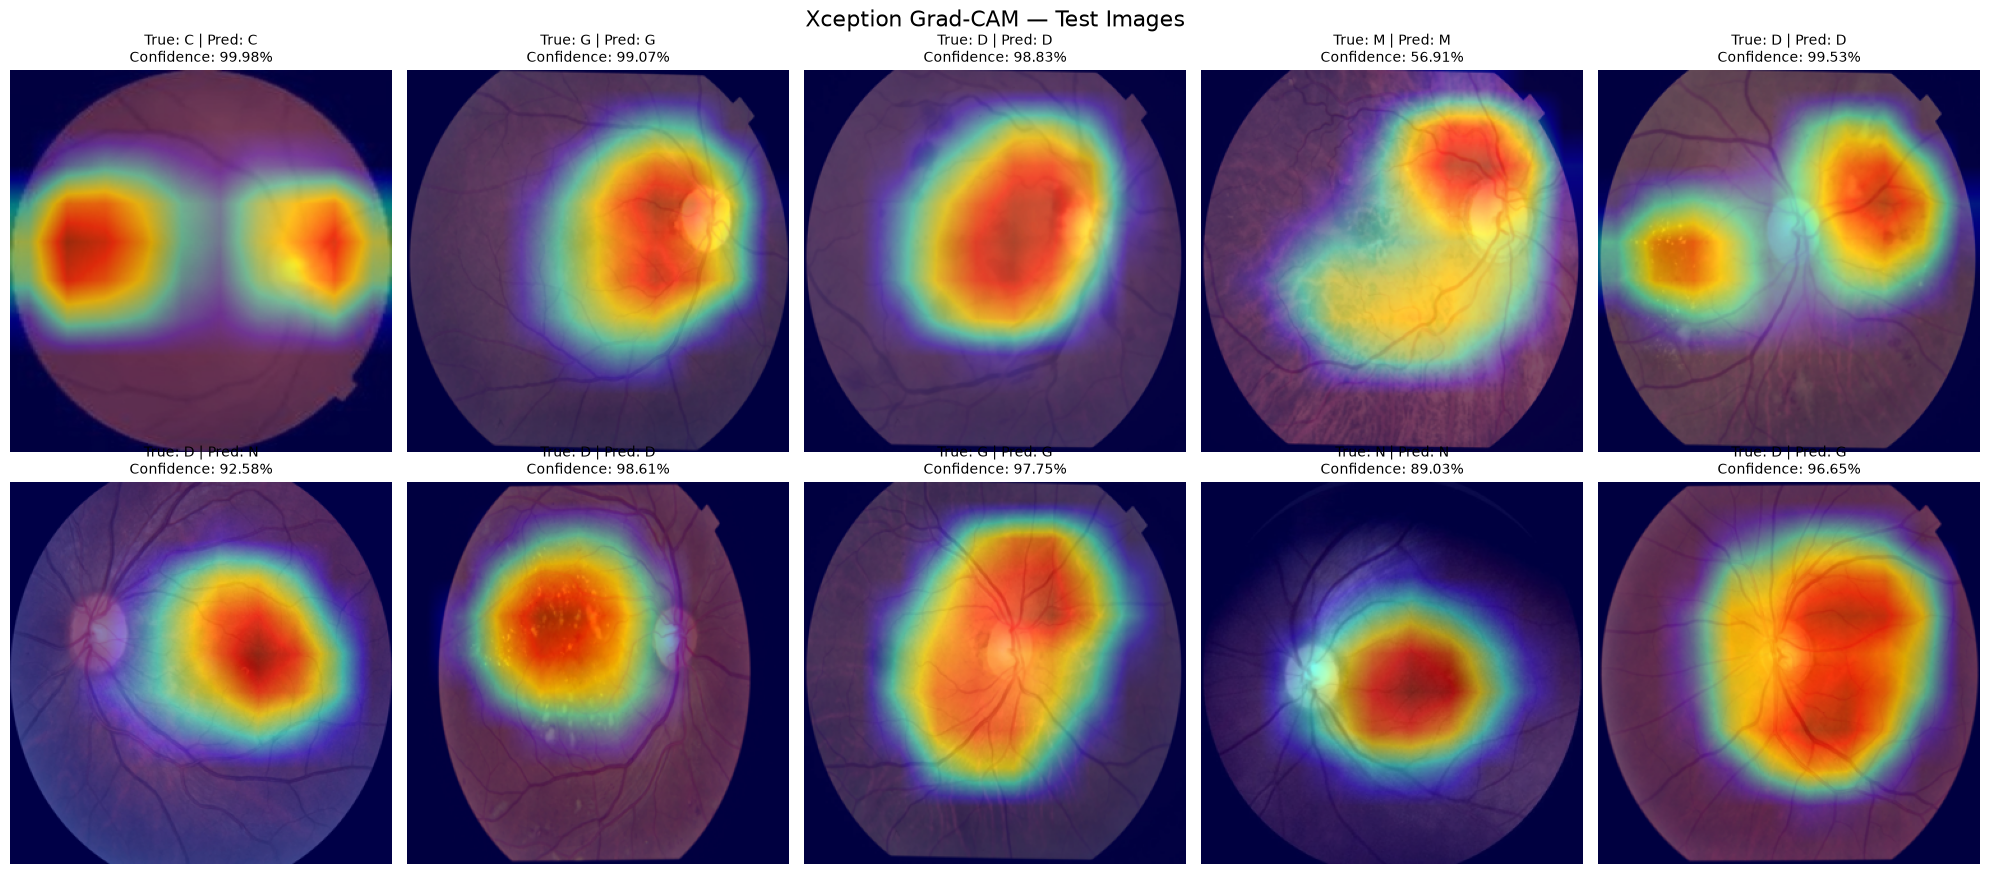

Contact sheet saved: D:\gpt\OcuVision-AI\results\xception\gradcam\xception_gradcam_contact_sheet.png

XCEPTION GRAD-CAM COMPLETE
Images generated: 10
Correct predictions: 8/10
Grad-CAM folder: D:\gpt\OcuVision-AI\results\xception\gradcam
Summary CSV: D:\gpt\OcuVision-AI\results\xception\gradcam\gradcam_summary.csv
Contact sheet: D:\gpt\OcuVision-AI\results\xception\gradcam\xception_gradcam_contact_sheet.png


In [15]:

# ============================================================
# XCEPTION — GRAD-CAM / XAI
# OcuVision-AI
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms

import timm

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(r"D:\gpt\OcuVision-AI")

RESULTS_DIR = PROJECT_ROOT / "results" / "xception"
CHECKPOINT_PATH = PROJECT_ROOT / "models" / "xception_best_checkpoint.pth"
SPLIT_PATH = RESULTS_DIR / "dataset_split.csv"

GRADCAM_DIR = RESULTS_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}"
    )

if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        f"Dataset split not found: {SPLIT_PATH}\n"
        "Run the training code that creates dataset_split.csv first."
    )


# ============================================================
# 2. DEVICE AND CLASSES
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

classes = ["N", "D", "G", "C", "A", "H", "M"]

idx_to_class = {
    idx: class_name
    for idx, class_name in enumerate(classes)
}


# ============================================================
# 3. LOAD TRAINED CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("\nCheckpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])

print(
    "Best validation Macro F1:",
    f"{checkpoint['best_val_macro_f1'] * 100:.2f}%"
)

# The training code used timm's "xception" model.
# In this timm version, that architecture is legacy_xception.
saved_model_name = checkpoint.get("model_name", "xception")

if saved_model_name == "xception":
    model_name = "legacy_xception"
else:
    model_name = saved_model_name

cam_model = timm.create_model(
    model_name,
    pretrained=False,
    num_classes=len(classes)
).to(device)

cam_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

cam_model.eval()

print("Architecture loaded:", model_name)


# ============================================================
# 4. LOAD THE SAVED TEST SPLIT
# ============================================================

split_df = pd.read_csv(SPLIT_PATH)

required_columns = {
    "image_path",
    "class",
    "label",
    "split"
}

missing_columns = required_columns - set(split_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns in split CSV: {missing_columns}"
    )

test_df = (
    split_df.loc[split_df["split"] == "test"]
    .reset_index(drop=True)
)

if test_df.empty:
    raise ValueError("No test images found in the saved split.")

print("Test images available:", len(test_df))


# ============================================================
# 5. IMAGE TRANSFORM
# ============================================================

IMG_SIZE = int(checkpoint.get("img_size", 299))

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 6. FIND GRAD-CAM TARGET LAYER
# ============================================================

conv_layers = [
    module
    for module in cam_model.modules()
    if isinstance(module, nn.Conv2d)
]

if not conv_layers:
    raise RuntimeError(
        "No convolutional layers found in the model."
    )

target_layer = conv_layers[-1]

print("\nGrad-CAM target layer:")
print(target_layer)


# ============================================================
# 7. INITIALIZE GRAD-CAM
# ============================================================

cam = GradCAM(
    model=cam_model,
    target_layers=[target_layer]
)


# ============================================================
# 8. SELECT UP TO 10 TEST IMAGES
# ============================================================

num_samples = min(10, len(test_df))

sample_indices = np.linspace(
    0,
    len(test_df) - 1,
    num_samples,
    dtype=int
)

selected_test_df = (
    test_df.iloc[sample_indices]
    .reset_index(drop=True)
)

print("\nSelected test images:")
print(
    selected_test_df[["image_path", "class"]]
    .to_string(index=False)
)


# ============================================================
# 9. GENERATE GRAD-CAM IMAGES
# ============================================================

gradcam_records = []

for sample_number in range(1, num_samples + 1):

    # Use iloc so the "class" column works without
    # the itertuples() reserved-keyword issue.
    row = selected_test_df.iloc[sample_number - 1]

    image_path = Path(row["image_path"])
    true_class = str(row["class"])

    if not image_path.exists():
        print(f"Skipping missing image: {image_path}")
        continue

    # Load and resize image
    with Image.open(image_path) as img:
        resized_image = img.convert("RGB").resize(
            (IMG_SIZE, IMG_SIZE)
        )

    rgb_image = (
        np.asarray(resized_image, dtype=np.float32) / 255.0
    )

    input_tensor = eval_transform(
        resized_image
    ).unsqueeze(0).to(device)

    # ---------------- PREDICTION ----------------

    with torch.no_grad():
        outputs = cam_model(input_tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predicted_index = int(
            probabilities.argmax(dim=1).item()
        )

        predicted_class = idx_to_class[predicted_index]

        confidence = float(
            probabilities[0, predicted_index].item()
        )

    # ---------------- GRAD-CAM ----------------

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[
            ClassifierOutputTarget(predicted_index)
        ]
    )[0]

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # ---------------- SAVE IMAGE ----------------

    output_filename = (
        f"{sample_number:02d}_{true_class}_"
        f"{predicted_class}_{confidence * 100:.2f}.png"
    )

    output_path = GRADCAM_DIR / output_filename

    Image.fromarray(visualization).save(output_path)

    gradcam_records.append({
        "sample": sample_number,
        "image_path": str(image_path),
        "true_class": true_class,
        "predicted_class": predicted_class,
        "confidence": confidence,
        "correct": predicted_class == true_class,
        "gradcam_path": str(output_path)
    })

    print(
        f"{sample_number:02d}/{num_samples} | "
        f"True: {true_class} | "
        f"Predicted: {predicted_class} | "
        f"Confidence: {confidence * 100:.2f}%"
    )


# ============================================================
# 10. SAVE GRAD-CAM SUMMARY CSV
# ============================================================

gradcam_df = pd.DataFrame(gradcam_records)

gradcam_csv = GRADCAM_DIR / "gradcam_summary.csv"

gradcam_df.to_csv(
    gradcam_csv,
    index=False
)

print("\nGrad-CAM summary saved:", gradcam_csv)


# ============================================================
# 11. CREATE CONTACT SHEET
# ============================================================

contact_sheet_path = (
    GRADCAM_DIR / "xception_gradcam_contact_sheet.png"
)

if not gradcam_df.empty:

    fig, axes = plt.subplots(
        2,
        5,
        figsize=(20, 9)
    )

    axes = axes.flatten()

    # Hide all unused axes first
    for ax in axes:
        ax.axis("off")

    for ax, record in zip(axes, gradcam_records):

        with Image.open(record["gradcam_path"]) as img:
            image = img.copy()

        ax.imshow(image)

        ax.set_title(
            f"True: {record['true_class']} | "
            f"Pred: {record['predicted_class']}\n"
            f"Confidence: {record['confidence'] * 100:.2f}%",
            fontsize=10
        )

        ax.axis("off")

    plt.suptitle(
        "Xception Grad-CAM — Test Images",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        contact_sheet_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Contact sheet saved:", contact_sheet_path)

else:
    print("No Grad-CAM images were generated.")


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

correct_count = (
    int(gradcam_df["correct"].sum())
    if not gradcam_df.empty
    else 0
)

print("\n" + "=" * 65)
print("XCEPTION GRAD-CAM COMPLETE")
print("=" * 65)

print("Images generated:", len(gradcam_df))
print(f"Correct predictions: {correct_count}/{len(gradcam_df)}")
print("Grad-CAM folder:", GRADCAM_DIR)
print("Summary CSV:", gradcam_csv)

if not gradcam_df.empty:
    print("Contact sheet:", contact_sheet_path)

print("=" * 65)


Device: cuda
External image: D:\gpt\OcuVision-AI\data\external_images\demo_fundus_image.jpg

Checkpoint loaded successfully.
Architecture: legacy_xception
Best epoch: 2
Best validation Macro F1: 84.98%
Original image size: (512, 512)

XCEPTION IMAGE PREDICTION
Predicted class: A
Model confidence: 99.50%

Class probabilities:
N: 0.09%
D: 0.04%
G: 0.17%
C: 0.11%
A: 99.50%
H: 0.02%
M: 0.08%

Grad-CAM target layer: Conv2d(1536, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)


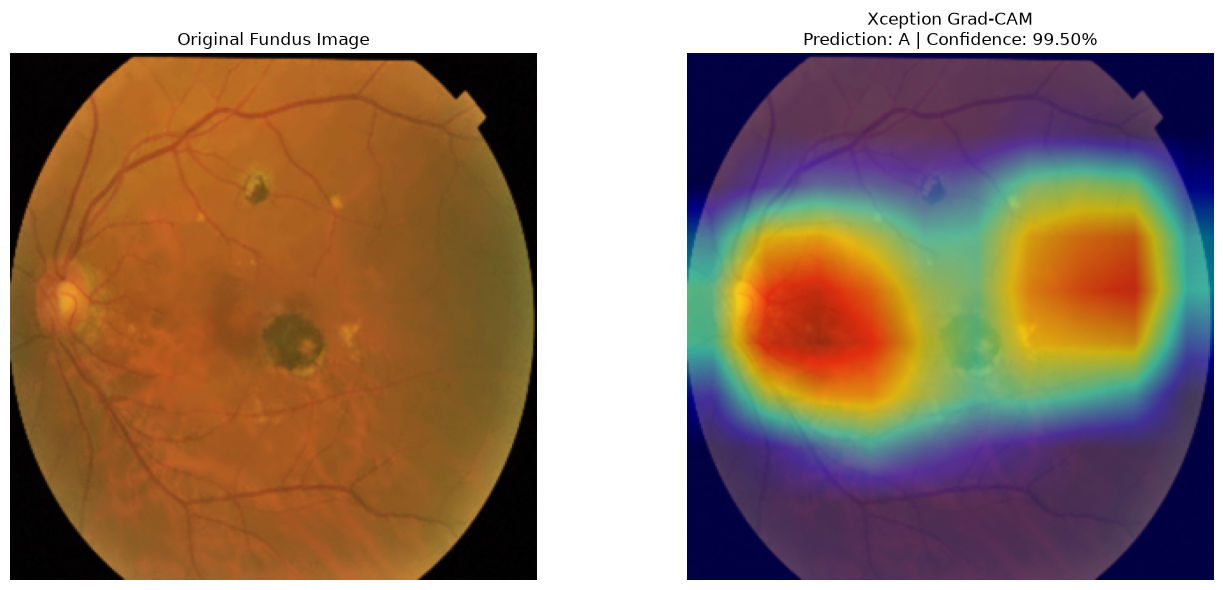


EXTERNAL INFERENCE + GRAD-CAM COMPLETE
Image: demo_fundus_image.jpg
Predicted class: A
Confidence: 99.50%
Grad-CAM image: D:\gpt\OcuVision-AI\results\xception\external_xai\xception_external_demo_fundus_image_A_99.50.png
Probability CSV: D:\gpt\OcuVision-AI\results\xception\external_xai\xception_external_demo_fundus_image_probabilities.csv

Research note: this is a model prediction, not a clinical diagnosis. Confidence is not the same as diagnostic certainty.


In [16]:

# ============================================================
# XCEPTION EXTERNAL IMAGE INFERENCE + GRAD-CAM
# OcuVision-AI | Standalone notebook cell
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms

import timm

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(r"D:\gpt\OcuVision-AI")

EXTERNAL_DIR = PROJECT_ROOT / "data" / "external_images"
RESULTS_DIR = PROJECT_ROOT / "results" / "xception"
CHECKPOINT_PATH = PROJECT_ROOT / "models" / "xception_best_checkpoint.pth"

EXTERNAL_XAI_DIR = RESULTS_DIR / "external_xai"

EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
EXTERNAL_XAI_DIR.mkdir(parents=True, exist_ok=True)

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Xception checkpoint not found:\n{CHECKPOINT_PATH}"
    )


# ============================================================
# 2. DEVICE AND CLASSES
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

classes = ["N", "D", "G", "C", "A", "H", "M"]

idx_to_class = {
    index: class_name
    for index, class_name in enumerate(classes)
}

print("Device:", device)


# ============================================================
# 3. FIND EXTERNAL IMAGE
# ============================================================

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

external_images = sorted(
    path for path in EXTERNAL_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
)

if not external_images:
    raise FileNotFoundError(
        "No external image found.\n\n"
        f"Add a real fundus image to:\n{EXTERNAL_DIR}\n\n"
        "Then rerun this cell."
    )

# Use the first image found. Change this to a specific filename
# if you want to predict a particular image.
EXTERNAL_IMAGE_PATH = external_images[0]

print("External image:", EXTERNAL_IMAGE_PATH)


# ============================================================
# 4. LOAD CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model_name = checkpoint.get("model_name", "xception")

# The trained timm "xception" checkpoint uses legacy_xception.
if model_name == "xception":
    model_name = "legacy_xception"

external_model = timm.create_model(
    model_name,
    pretrained=False,
    num_classes=len(classes)
).to(device)

external_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

external_model.eval()

print("\nCheckpoint loaded successfully.")
print("Architecture:", model_name)
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation Macro F1:",
    f"{checkpoint['best_val_macro_f1'] * 100:.2f}%"
)


# ============================================================
# 5. PREPROCESS IMAGE
# ============================================================

IMG_SIZE = int(checkpoint.get("img_size", 299))

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

with Image.open(EXTERNAL_IMAGE_PATH) as image:
    original_image = image.convert("RGB")

resized_image = original_image.resize((IMG_SIZE, IMG_SIZE))

rgb_image = (
    np.asarray(resized_image, dtype=np.float32) / 255.0
)

input_tensor = eval_transform(
    resized_image
).unsqueeze(0).to(device)

print("Original image size:", original_image.size)


# ============================================================
# 6. PREDICT CLASS
# ============================================================

with torch.no_grad():
    outputs = external_model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

predicted_index = int(probabilities.argmax().item())
predicted_class = idx_to_class[predicted_index]
confidence = float(probabilities[predicted_index].item())

print("\n" + "=" * 60)
print("XCEPTION IMAGE PREDICTION")
print("=" * 60)
print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence * 100:.2f}%")
print("\nClass probabilities:")

probability_records = []

for index, class_name in enumerate(classes):
    probability = float(probabilities[index].item())

    probability_records.append({
        "class": class_name,
        "probability": probability,
        "probability_percent": probability * 100
    })

    print(f"{class_name}: {probability * 100:.2f}%")


# ============================================================
# 7. FIND GRAD-CAM TARGET LAYER
# ============================================================

conv_layers = [
    module for module in external_model.modules()
    if isinstance(module, nn.Conv2d)
]

if not conv_layers:
    raise RuntimeError("No convolutional layers found.")

target_layer = conv_layers[-1]

print("\nGrad-CAM target layer:", target_layer)


# ============================================================
# 8. GENERATE GRAD-CAM
# ============================================================

with GradCAM(
    model=external_model,
    target_layers=[target_layer]
) as cam:

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(predicted_index)]
    )[0]

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)


# ============================================================
# 9. DISPLAY ORIGINAL IMAGE AND GRAD-CAM
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(resized_image)
axes[0].set_title("Original Fundus Image")
axes[0].axis("off")

axes[1].imshow(visualization)
axes[1].set_title(
    f"Xception Grad-CAM\n"
    f"Prediction: {predicted_class} | "
    f"Confidence: {confidence * 100:.2f}%"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)


# ============================================================
# 10. SAVE GRAD-CAM AND PROBABILITIES
# ============================================================

output_path = (
    EXTERNAL_XAI_DIR /
    f"xception_external_{EXTERNAL_IMAGE_PATH.stem}_"
    f"{predicted_class}_{confidence * 100:.2f}.png"
)

Image.fromarray(visualization).save(output_path)

probability_df = pd.DataFrame(probability_records)

probability_csv = (
    EXTERNAL_XAI_DIR /
    f"xception_external_{EXTERNAL_IMAGE_PATH.stem}_probabilities.csv"
)

probability_df.to_csv(probability_csv, index=False)


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("EXTERNAL INFERENCE + GRAD-CAM COMPLETE")
print("=" * 60)
print("Image:", EXTERNAL_IMAGE_PATH.name)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")
print("Grad-CAM image:", output_path)
print("Probability CSV:", probability_csv)
print("=" * 60)

print(
    "\nResearch note: this is a model prediction, not a clinical "
    "diagnosis. Confidence is not the same as diagnostic certainty."
)
